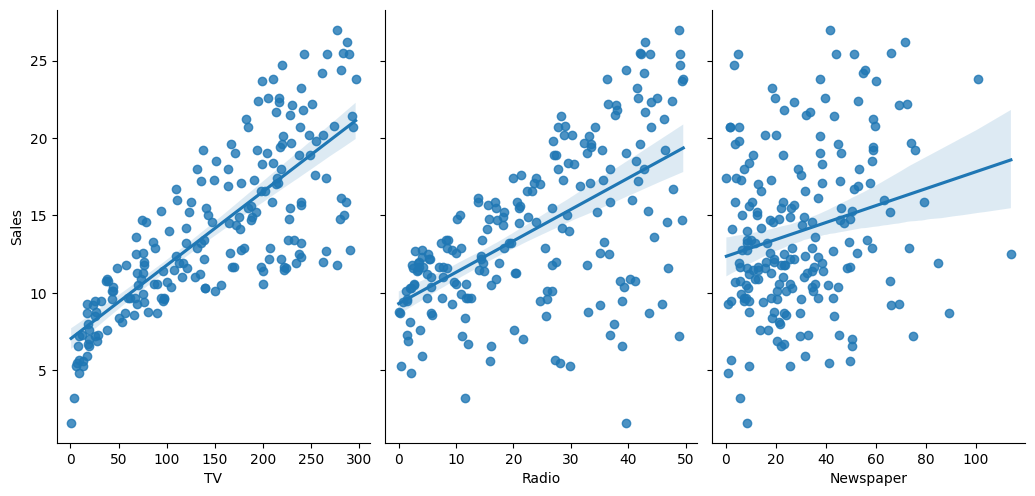

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar desde URL (Repositorio oficial de scikit-learn videos)
url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
adv = pd.read_csv(url, index_col=0)

# 2. Visualizar relaciones
# 'x_vars' son los canales, 'y_vars' son las ventas
sns.pairplot(adv, x_vars=['TV', 'Radio', 'Newspaper'], y_vars='Sales', height=5, aspect=0.7, kind='reg')
plt.show()

In [17]:
adv.head(50)

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9
6,8.7,48.9,75.0,7.2
7,57.5,32.8,23.5,11.8
8,120.2,19.6,11.6,13.2
9,8.6,2.1,1.0,4.8
10,199.8,2.6,21.2,10.6


In [11]:
from sklearn.model_selection import train_test_split

#Definir variables predictoras y variable objetivo
X = adv[['TV', 'Radio', 'Newspaper']]
y = adv['Sales']

#Separar datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

print("Datos separados correctamente")

Datos separados correctamente


In [12]:
from sklearn.linear_model import LinearRegression

# Entrenar el modelo
lm = LinearRegression()
lm.fit(X_train, y_train)

# Intercepto del modelo
print(f"Intercepto: {lm.intercept_}")

Intercepto: 2.901313692873174


In [13]:
cdf = pd.DataFrame(lm.coef_, X.columns, columns=['Coeff'])
print(cdf)

              Coeff
TV         0.045328
Radio      0.189941
Newspaper  0.000274


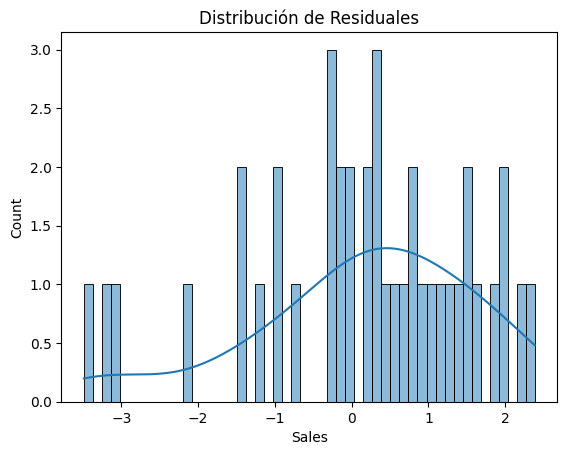

In [16]:
# Hacer predicciones
predictions = lm.predict(X_test)

sns.histplot((y_test - predictions), bins=50, kde=True)
plt.title("Distribución de Residuales")
plt.show()

In [15]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predicciones sobre el conjunto de prueba
y_pred = lm.predict(X_test)

# Calcular RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE: {rmse:.2f}')

# Calcular R2
r2 = r2_score(y_test, y_pred)
print(f'R2: {r2:.2f}')

RMSE: 1.44
R2: 0.93
